# Notebook 2: Diagnostics and Conclusions

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.gofplots import qqplot

sns.set_theme(style="whitegrid")

OUT = Path("../outputs")
T, M, FIG = OUT / "tables", OUT / "models", OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(OUT / "data" / "prepared_monthly_genre_share.csv", index_col=0, parse_dates=True)
GENRES = list(df.columns)

ranking = pd.read_csv(T / "model_rankings.csv")
sel = ranking[ranking["selected"]].set_index("genre").loc[GENRES]      # selected model per genre
test_raw = pd.read_csv(T / "test_metrics_raw.csv", index_col=0)
test_norm = pd.read_csv(T / "test_metrics_normalized.csv", index_col=0)
summary = pd.read_csv(T / "forecast_summary.csv", index_col=0)
residuals = pd.read_csv(M / "residuals.csv", index_col=0, parse_dates=True)
selected = json.load(open(M / "selected_models.json"))

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

1. Model Performance 📊

</div>

In [2]:
# Validation RMSE of the best model in each family (lower is better) and the selected family
display(ranking.pivot(index="genre", columns="family", values="val_RMSE").round(3).assign(selected=sel["family"]))

# Test performance of the selected models: raw vs normalized predictions
perf = sel[["params"]].join(test_raw.add_prefix("raw_")).join(test_norm.add_prefix("norm_"))
display(perf.round(3))
display(pd.concat({"raw": test_raw, "normalized": test_norm}, axis=1).loc[["All genres (pooled)"]].round(3))

family,ARIMA,ETS,selected
genre,,,
Action,0.661,0.691,ARIMA
Adventure,0.505,0.387,ETS
Comedy,0.443,0.444,ARIMA
Drama,1.600,2.205,ARIMA
Romance,0.618,0.322,ETS
Sci-Fi,0.620,0.228,ETS
Thriller,0.391,0.607,ARIMA


,params,raw_MAE,raw_RMSE,raw_MAPE,norm_MAE,norm_RMSE,norm_MAPE
genre,,,,,,,
Action,"ARIMA(0,1,0), trend=n",0.390,0.493,2.349,0.328,0.426,1.964
Adventure,"ETS(error=add, trend=add, damped=False, season...",0.655,0.767,4.957,0.557,0.659,4.214
Comedy,"ARIMA(0,1,2), trend=n",0.422,0.539,2.609,0.481,0.617,2.965
Drama,"ARIMA(0,1,0), trend=n",0.501,0.590,2.290,0.544,0.642,2.469
Romance,"ETS(error=add, trend=add, damped=False, season...",0.214,0.265,3.133,0.248,0.299,3.631
Sci-Fi,"ETS(error=add, trend=add, damped=False, season...",0.645,0.743,5.922,0.569,0.652,5.229
Thriller,"ARIMA(0,0,2), trend=c",0.398,0.521,2.745,0.465,0.599,3.201


raw               normalized              
                       MAE   RMSE   MAPE        MAE   RMSE   MAPE
All genres (pooled)  0.461  0.581  3.429      0.456  0.571  3.382

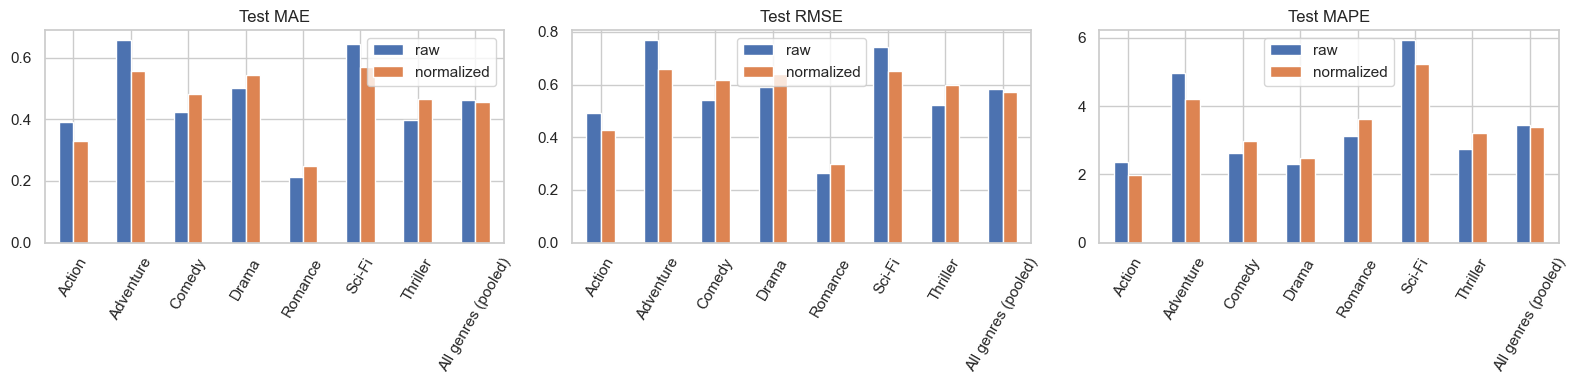

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(axes, ["MAE", "RMSE", "MAPE"]):
    pd.DataFrame({"raw": test_raw[m], "normalized": test_norm[m]}).plot.bar(ax=ax)
    ax.set_title(f"Test {m}")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
fig.savefig(FIG / "test_metrics_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

**Observations**
* ARIMA won for Action, Comedy, Drama and Thriller. ETS (additive trend) won for Adventure, Romance and Sci-Fi.
* Pooled test error is small: MAE 0.46 pp, RMSE 0.57 pp, MAPE about 3.4%. Normalizing gave almost the same pooled result (0.456, 0.571, 3.38%).
* Normalization helped Action, Adventure and Sci-Fi, and made Comedy, Drama, Romance and Thriller slightly worse.
* Best genre by MAPE: Action (1.96%). Weakest: Sci-Fi (5.23%).
* Romance has the lowest RMSE (0.30 pp), but its MAPE is not the lowest because its share is small.

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

2. Residual Diagnostics 🔍

</div>

Residuals are the one-step errors of each selected model fitted on all data. Start-up residuals were already dropped in the modeling notebook.

* **Jarque-Bera:** p < 0.05 means the residuals are not normal.
* **Ljung-Box (lags 12 and 24):** p < 0.05 means the residuals are still autocorrelated (the model missed some pattern).

Normal residuals are **not required** for a forecasting model. They matter mostly for prediction intervals, not for point forecasts.

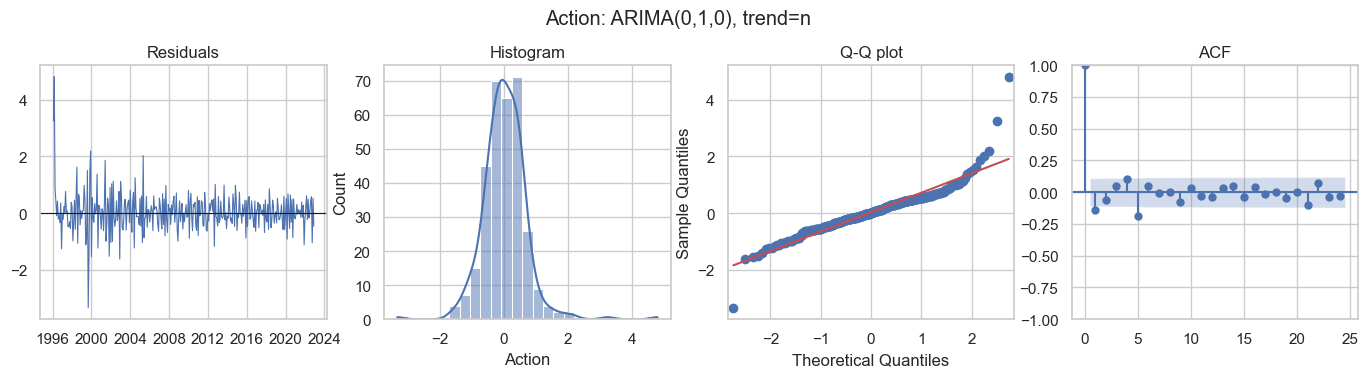

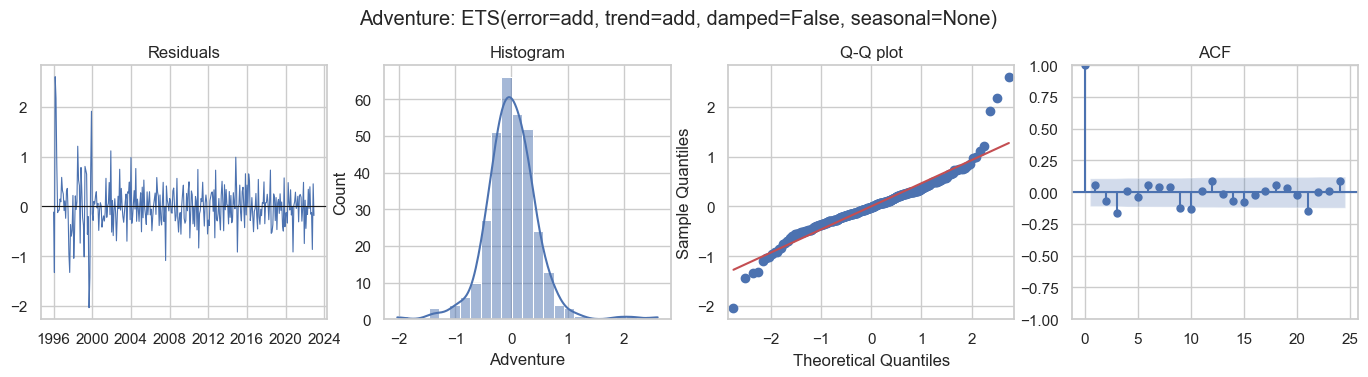

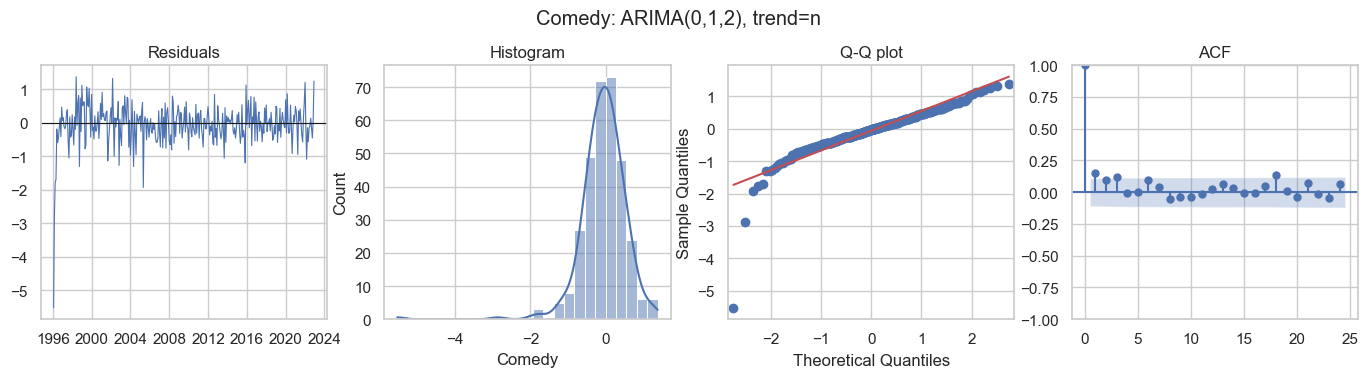

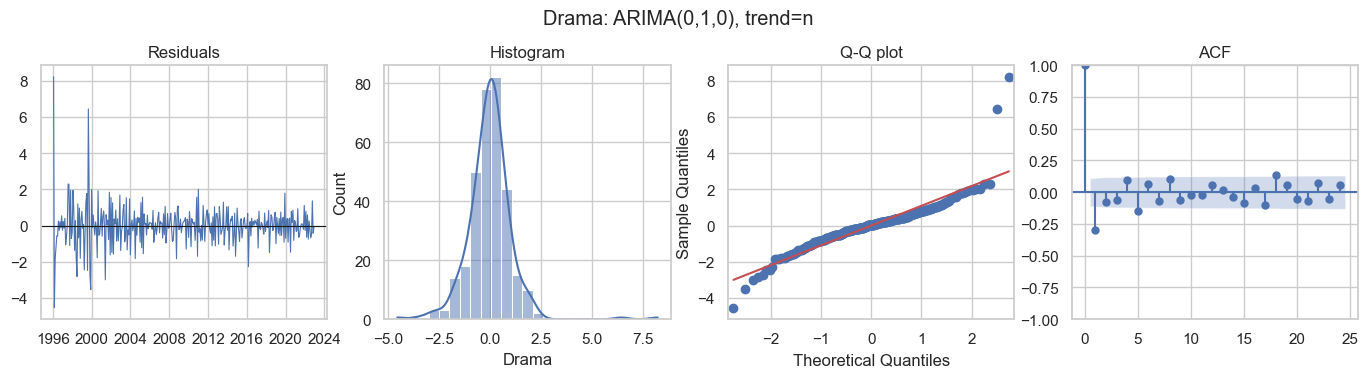

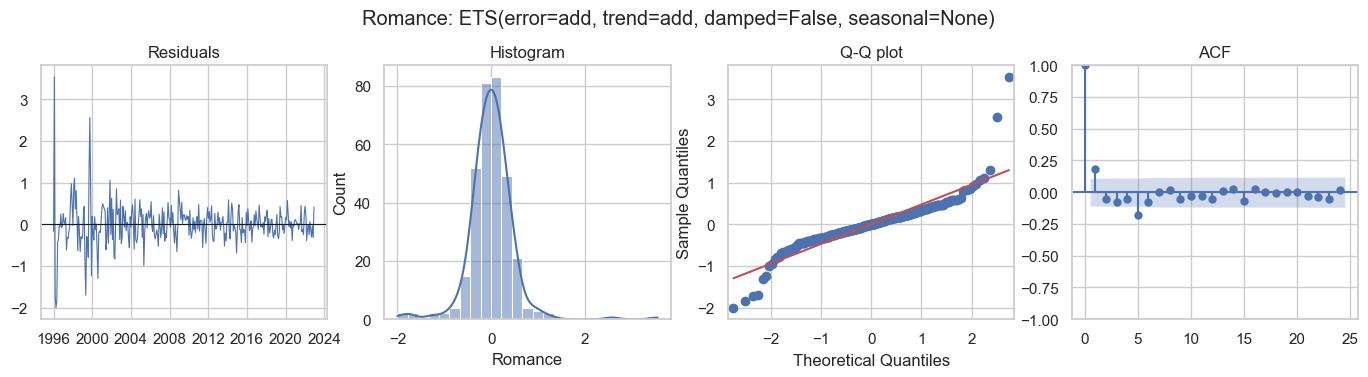

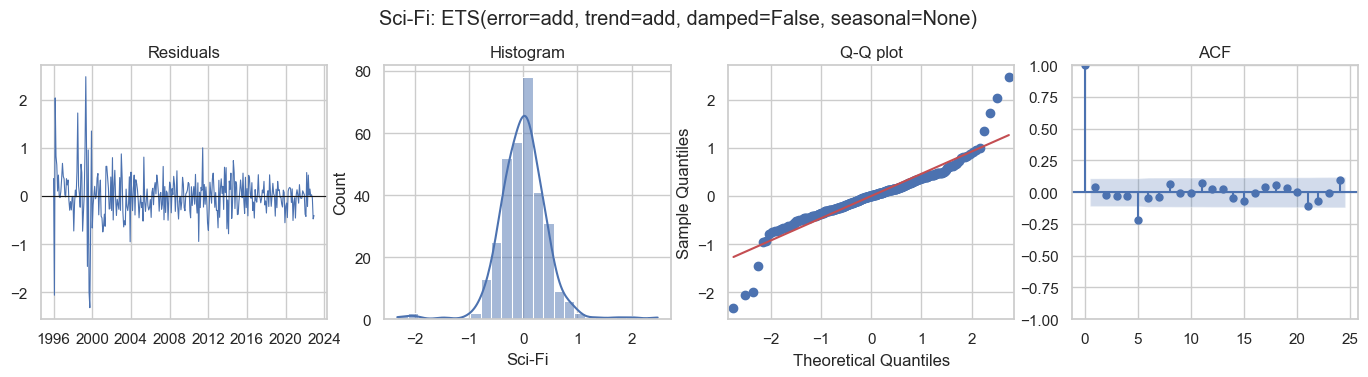

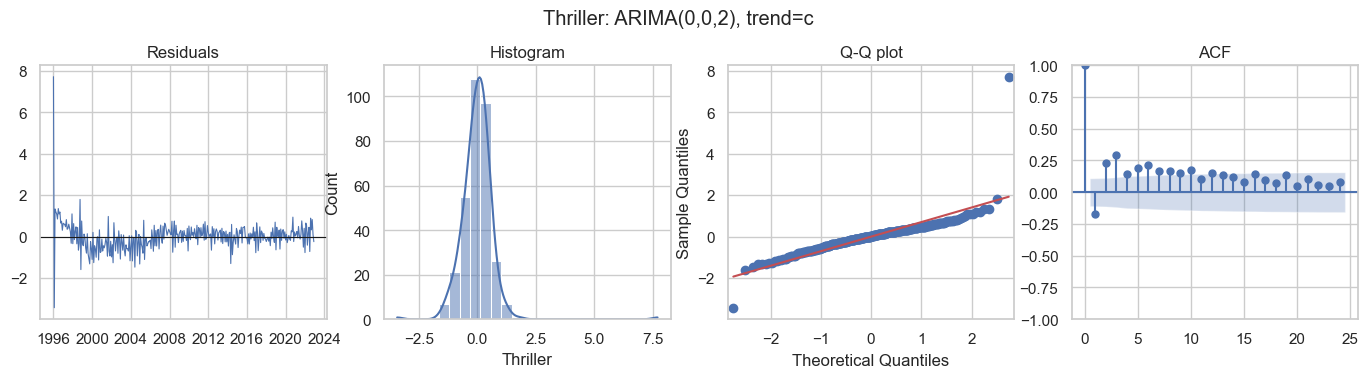

,min,Q1,median,Q3,max,JB_stat,JB_p,LB12_p,LB24_p,normal_residuals,no_autocorrelation
genre,,,,,,,,,,,
Action,-3.3331,-0.3364,0.0012,0.4231,4.8067,1312.7085,0.0,0.0056,0.0441,No,No
Adventure,-2.0337,-0.2555,-0.0136,0.2494,2.6030,455.7019,0.0,0.0051,0.0061,No,No
Comedy,-5.5237,-0.3598,-0.0236,0.2868,1.3763,5831.0354,0.0,0.0195,0.0434,No,No
Drama,-4.5348,-0.5200,0.0384,0.4521,8.2267,2538.4633,0.0,0.0000,0.0000,No,No
Romance,-2.0040,-0.2216,-0.0007,0.2117,3.5421,2497.9735,0.0,0.0026,0.0859,No,No
Sci-Fi,-2.3199,-0.2424,0.0027,0.2319,2.4786,671.0505,0.0,0.0370,0.0580,No,No
Thriller,-3.4321,-0.3315,0.0046,0.3093,7.7043,27498.8497,0.0,0.0000,0.0000,No,No


Normality rejected for 7 of 7 genres. Autocorrelation found for 7 of 7 genres.


In [4]:
rows = []
for g in GENRES:
    r = residuals[g].dropna()
    jb = jarque_bera(r.values)
    lb = acorr_ljungbox(r, lags=[12, 24], model_df=selected[g]["model_df"], return_df=True)
    rows.append({"genre": g, **dict(zip(["min", "Q1", "median", "Q3", "max"], r.quantile([0, .25, .5, .75, 1]))),
                 "JB_stat": jb.statistic, "JB_p": jb.pvalue,
                 "LB12_p": lb.loc[12, "lb_pvalue"], "LB24_p": lb.loc[24, "lb_pvalue"]})

    fig, ax = plt.subplots(1, 4, figsize=(17, 3.3))
    ax[0].plot(r.index, r.values, lw=0.8); ax[0].axhline(0, color="k", lw=0.8); ax[0].set_title("Residuals")
    sns.histplot(r, kde=True, bins=25, ax=ax[1]); ax[1].set_title("Histogram")
    qqplot(r.values, line="s", ax=ax[2]); ax[2].set_title("Q-Q plot")
    plot_acf(r.values, lags=24, ax=ax[3]); ax[3].set_title("ACF")
    fig.suptitle(f"{g}: {selected[g]['model']}", y=1.05)
    fig.savefig(FIG / f"residuals_{g}.png", dpi=110, bbox_inches="tight")
    plt.show()

diag = pd.DataFrame(rows).set_index("genre")
diag["normal_residuals"] = np.where(diag["JB_p"] < 0.05, "No", "Yes")
diag["no_autocorrelation"] = np.where(diag[["LB12_p", "LB24_p"]].min(axis=1) < 0.05, "No", "Yes")
diag.to_csv(T / "residual_diagnostics.csv")
display(diag.round(4))
print(f"Normality rejected for {(diag['normal_residuals'] == 'No').sum()} of {len(GENRES)} genres. "
      f"Autocorrelation found for {(diag['no_autocorrelation'] == 'No').sum()} of {len(GENRES)} genres.")

**Observations** *(add after running: look at the Q-Q plots for heavy tails, and the ACF bars outside the blue band)*
* Mean and median near 0 mean the models do not over- or under-forecast on average.
* Heavy tails or outliers show as points leaving the Q-Q line and a small Jarque-Bera p-value. This affects prediction intervals more than point forecasts.
* Genres with "No" under `no_autocorrelation` still have some pattern the model missed.
* These are in-sample checks. The test metrics in Section 1 show real out-of-sample accuracy.

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

3. Final Interpretation 🎯

</div>

In [5]:
final = summary[["historical_avg", "forecast_avg", "change_pp"]].copy()
final["direction"] = np.select([final["change_pp"] > 0.5, final["change_pp"] < -0.5], ["gaining", "losing"], "stable")
final["selected_model"] = sel["params"]
final[["test_MAE", "test_RMSE", "test_MAPE"]] = test_norm.loc[final.index, ["MAE", "RMSE", "MAPE"]].values
display(final.round(2))
final.to_csv(T / "final_summary_table.csv")

,historical_avg,forecast_avg,change_pp,direction,selected_model,test_MAE,test_RMSE,test_MAPE
Drama,22.69,22.14,-0.56,losing,"ARIMA(0,1,0), trend=n",0.54,0.64,2.47
Action,15.23,17.06,1.83,gaining,"ARIMA(0,1,0), trend=n",0.33,0.43,1.96
Comedy,18.11,16.06,-2.06,losing,"ARIMA(0,1,2), trend=n",0.48,0.62,2.97
Thriller,13.96,14.08,0.12,stable,"ARIMA(0,0,2), trend=c",0.46,0.60,3.20
Adventure,11.93,13.37,1.44,gaining,"ETS(error=add, trend=add, damped=False, season...",0.56,0.66,4.21
Sci-Fi,8.97,11.11,2.13,gaining,"ETS(error=add, trend=add, damped=False, season...",0.57,0.65,5.23
Romance,9.11,6.19,-2.92,losing,"ETS(error=add, trend=add, damped=False, season...",0.25,0.30,3.63


Direction rule: change above +0.5 pp = gaining, below -0.5 pp = losing, otherwise stable. Test metrics are for the normalized predictions.

**Observations**
* **Drama** stays the biggest genre (about 22.1%) but dips slightly (-0.56 pp).
* **Gaining:** Sci-Fi (+2.13 pp), Action (+1.83 pp), Adventure (+1.44 pp).
* **Losing:** Romance (-2.92 pp) and Comedy (-2.06 pp).
* **Stable:** Thriller (+0.12 pp).
* The change is measured against the 27-year average, so it partly reflects trends that already happened. For example, Romance was already near 6.7% in the last 3 years.

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

4. Conclusion ✅

</div>

In [6]:
n_jb = int((diag["normal_residuals"] == "No").sum())
n_lb = int((diag["no_autocorrelation"] == "No").sum())
print(f"Diagnostics: normality rejected for {n_jb} of {len(GENRES)} genres; autocorrelation left in {n_lb} of {len(GENRES)} genres.")

Diagnostics: normality rejected for 7 of 7 genres; autocorrelation left in 7 of 7 genres.


* **Best models:** ARIMA for Action, Comedy, Drama, Thriller; ETS with additive trend for Adventure, Romance, Sci-Fi. SARIMA was not needed because seasonality was weak.
* **Accuracy:** on the 48-month test set the pooled error is about 0.46 pp MAE and 3.4% MAPE, so the forecasts are close to the actual shares.
* **Forecast:** Sci-Fi, Action and Adventure gain share. Romance and Comedy lose share. Thriller is stable. Drama stays on top with a small dip.
* **Diagnostics:** see the line printed above. Non-normal residuals do not make the point forecasts wrong, but prediction intervals should be used with care.
* **Main finding:** movie genre shares follow slow trends rather than seasons, so simple trend models (random-walk ARIMA and trend ETS) forecast them well.
* **Limit:** the forecasts assume recent trends continue and cannot predict sudden market changes.